In [76]:
library(caret)
library(readr)
library(corrplot)
library(ggplot2)
library(dplyr)
library(BayesTree)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(reshape2)
library(car)

In [75]:
pkgs <- c("caret", "readr", "corrplot", "ggplot2", "dplyr", 
          "BayesTree", "gridExtra", "reshape2", "car")

invisible(lapply(pkgs, function(pkg) {
  suppressMessages(
    suppressWarnings(
      suppressPackageStartupMessages(
        library(pkg, character.only = TRUE)
      )
    )
  )
}))

## 1. EDA

In [77]:
myData <- read.csv("online_shoppers_intention.csv")

### Features

In [78]:
## 1.  Administrative : # of pages of this type (administrative) that the user visited.
## 2.  Administrative_Duration : the amount of time spent in this category of pages
## 3.  Informational : # of pages of this type (informational) that the user visited.
## 4.  Informational_Duration : the amount of time spent in this category of pages.
## 5.  ProductRelated : # of pages of this type (product related) that the user visited.
## 6.  ProductRelated_Duration : the amount of time spent in this category of pages.
## 7.  BounceRates : The percentage of visitors who enter the website through that page and exit without triggering any additional tasks.
## 8.  ExitRates : The average value of the page averaged over the value of the target page and/or the completion of an eCommerce
## 9.  PageValues : The average value of the pages visited by the user. This metric is often used as an indicator of how valuable a page is in terms of generating revenue.
## 10. SpecialDay : the closeness of the site visiting time to a specific special day (e.g., Mother’s Day, Valentine's Day) in which the sessions are more likely to be finalized with a transaction

## 11. Month
## 12. OperatingSystems
## 13. Browser : The browser used by the user.
## 14. Region : The region from which the user is accessing the website.
## 15. TrafficType : The type of traffic (e.g., direct, paid search, organic search, referral).
## 16. VisitorType : A categorization of users (e.g., Returning Visitor, New Visitor).
## 17. Weekend : A boolean indicating whether the session occurred on a weekend.

## 18. Revenue : A binary variable indicating whether the session ended in a transaction (purchase).

### 1) Data Check

In [79]:
head(myData)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<chr>,<lgl>,<lgl>
1,0,0,0,0,1,0.000000,0.20000000,0.2000000,0,0,Feb,1,1,1,1,Returning_Visitor,FALSE,FALSE
2,0,0,0,0,2,64.000000,0.00000000,0.1000000,0,0,Feb,2,2,1,2,Returning_Visitor,FALSE,FALSE
3,0,0,0,0,1,0.000000,0.20000000,0.2000000,0,0,Feb,4,1,9,3,Returning_Visitor,FALSE,FALSE
4,0,0,0,0,2,2.666667,0.05000000,0.1400000,0,0,Feb,3,2,2,4,Returning_Visitor,FALSE,FALSE
5,0,0,0,0,10,627.500000,0.02000000,0.0500000,0,0,Feb,3,3,1,4,Returning_Visitor,TRUE,FALSE
6,0,0,0,0,19,154.216667,0.01578947,0.0245614,0,0,Feb,2,2,1,3,Returning_Visitor,FALSE,FALSE


In [80]:
dim(myData)

[1] 12330    18

In [81]:
summary(myData)

 Administrative   Administrative_Duration Informational    
 Min.   : 0.000   Min.   :   0.00         Min.   : 0.0000  
 1st Qu.: 0.000   1st Qu.:   0.00         1st Qu.: 0.0000  
 Median : 1.000   Median :   7.50         Median : 0.0000  
 Mean   : 2.315   Mean   :  80.82         Mean   : 0.5036  
 3rd Qu.: 4.000   3rd Qu.:  93.26         3rd Qu.: 0.0000  
 Max.   :27.000   Max.   :3398.75         Max.   :24.0000  
 Informational_Duration ProductRelated   ProductRelated_Duration
 Min.   :   0.00        Min.   :  0.00   Min.   :    0.0        
 1st Qu.:   0.00        1st Qu.:  7.00   1st Qu.:  184.1        
 Median :   0.00        Median : 18.00   Median :  598.9        
 Mean   :  34.47        Mean   : 31.73   Mean   : 1194.8        
 3rd Qu.:   0.00        3rd Qu.: 38.00   3rd Qu.: 1464.2        
 Max.   :2549.38        Max.   :705.00   Max.   :63973.5        
  BounceRates         ExitRates         PageValues        SpecialDay     
 Min.   :0.000000   Min.   :0.00000   Min.   :  0.0

In [82]:
table(myData$Revenue)


FALSE  TRUE 
10422  1908 

In [83]:
threshold <- 1908/10422 #ratio of two classes -> threshold

In [84]:
str(myData)

'data.frame':	12330 obs. of  18 variables:
 $ Administrative         : int  0 0 0 0 0 0 0 1 0 0 ...
 $ Administrative_Duration: num  0 0 0 0 0 0 0 0 0 0 ...
 $ Informational          : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Informational_Duration : num  0 0 0 0 0 0 0 0 0 0 ...
 $ ProductRelated         : int  1 2 1 2 10 19 1 0 2 3 ...
 $ ProductRelated_Duration: num  0 64 0 2.67 627.5 ...
 $ BounceRates            : num  0.2 0 0.2 0.05 0.02 ...
 $ ExitRates              : num  0.2 0.1 0.2 0.14 0.05 ...
 $ PageValues             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ SpecialDay             : num  0 0 0 0 0 0 0.4 0 0.8 0.4 ...
 $ Month                  : chr  "Feb" "Feb" "Feb" "Feb" ...
 $ OperatingSystems       : int  1 2 4 3 3 2 2 1 2 2 ...
 $ Browser                : int  1 2 1 2 3 2 4 2 2 4 ...
 $ Region                 : int  1 1 9 2 1 1 3 1 2 1 ...
 $ TrafficType            : int  1 2 3 4 4 3 3 5 3 2 ...
 $ VisitorType            : chr  "Returning_Visitor" "Returning_Visitor" "Returning_Visito

### 2) Data Preprocessing 

In [85]:
myData$Month <- as.factor(myData$Month)
myData$OperatingSystems <- as.factor(myData$OperatingSystems)
myData$Browser <- as.factor(myData$Browser)
myData$Region <- as.factor(myData$Region)
myData$TrafficType <- as.factor(myData$TrafficType)

### 3) Unique Value Analysis(categorical features)

In [86]:
unique(myData$Month)
unique(myData$OperatingSystems)
unique(myData$Browser)
unique(myData$Region)
unique(myData$TrafficType)
unique(myData$VisitorType)
unique(myData$Weekend)
unique(myData$Revenue)

[1] Feb  Mar  May  Oct  June Jul  Aug  Nov  Sep  Dec 
Levels: Aug Dec Feb Jul June Mar May Nov Oct Sep

[1] 1 2 4 3 7 6 8 5
Levels: 1 2 3 4 5 6 7 8

[1] 1  2  3  4  5  6  7  10 8  9  12 13 11
Levels: 1 2 3 4 5 6 7 8 9 10 11 12 13

[1] 1 9 2 3 4 5 6 7 8
Levels: 1 2 3 4 5 6 7 8 9

[1] 1  2  3  4  5  6  7  8  9  10 11 12 13 14 15 18 19 16 17 20
Levels: 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20

[1] "Returning_Visitor" "New_Visitor"       "Other"

[1] FALSE  TRUE

[1] FALSE  TRUE

In [87]:
# Rename "June" to "Jun"

In [88]:
levels(myData$Month)[levels(myData$Month)=="June"] <- "Jun"
unique(myData$Month)

[1] Feb Mar May Oct Jun Jul Aug Nov Sep Dec
Levels: Aug Dec Feb Jul Jun Mar May Nov Oct Sep

### 4) Missing value analysis

In [89]:
sum(is.na(myData))

[1] 0

### 5) Correlation Analysis

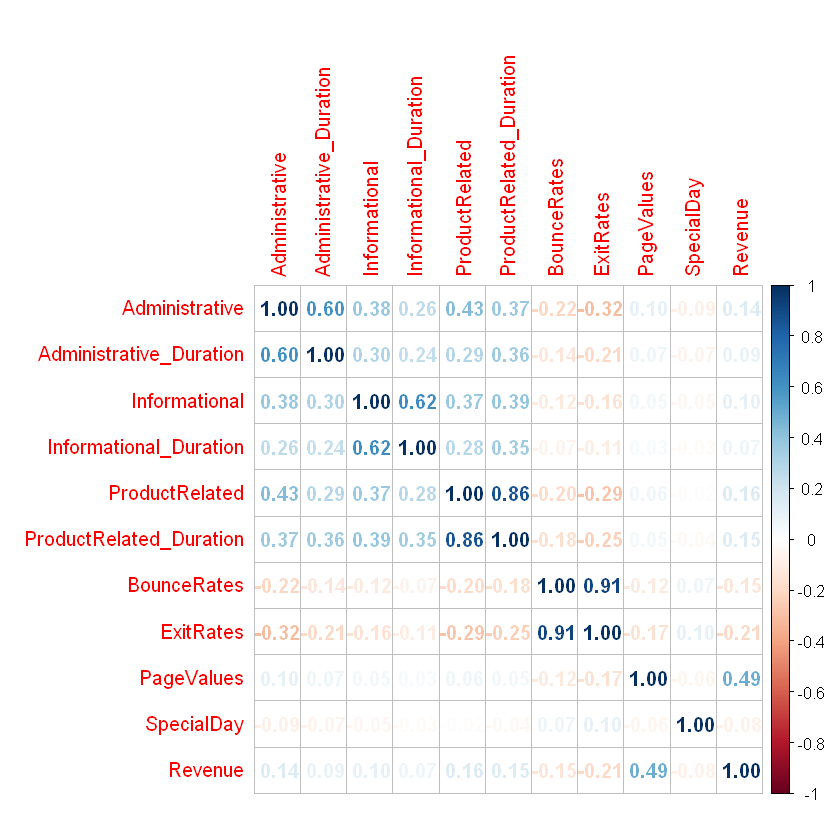

In [90]:
numeric_list = c('Administrative', 'Administrative_Duration','Informational','Informational_Duration','ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Revenue')
c <- round(cor(myData[,numeric_list]), 2)
corrplot(c, method = "number")

### 6) Weekend and Revenue Analysis

In [91]:
table(myData$Weekend, myData$Revenue)

       
        FALSE TRUE
  FALSE  8053 1409
  TRUE   2369  499

In [92]:
#Perform the Chi-Square Test
chisq.test(myData$Weekend, myData$Revenue, correct = FALSE)


	Pearson's Chi-squared test

data:  myData$Weekend and myData$Revenue
X-squared = 10.582, df = 1, p-value = 0.001142


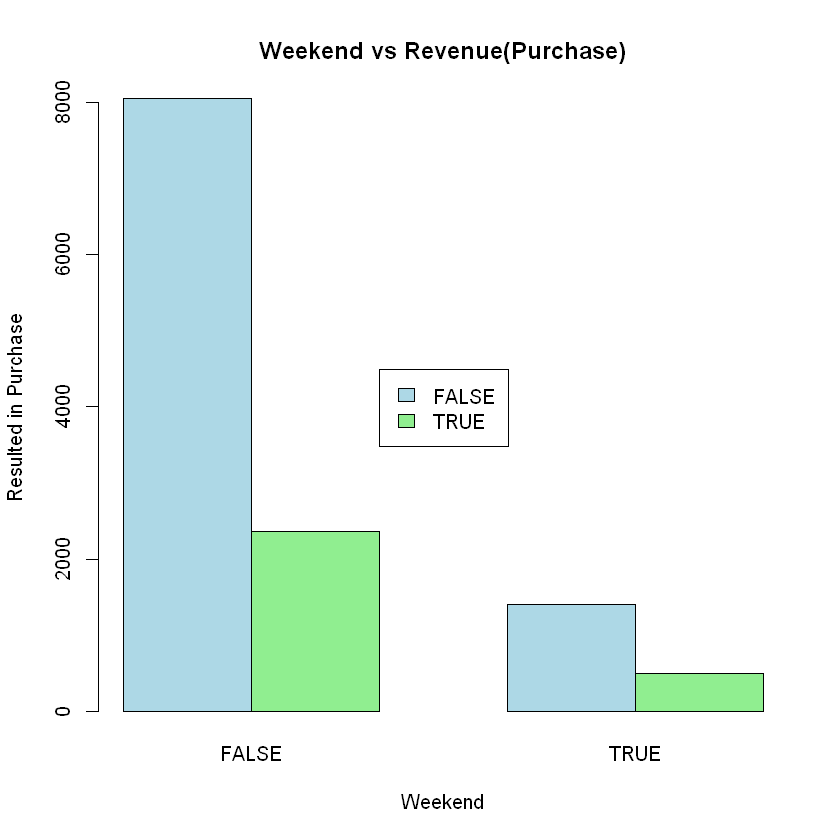

In [93]:
Weekend_R <- table(myData$Weekend, myData$Revenue)
barplot(Weekend_R, beside = TRUE, col = c("lightblue", "lightgreen"),
        main = "Weekend vs Revenue(Purchase)",
        xlab = "Weekend", ylab = "Resulted in Purchase")

legend("center", legend = rownames(Weekend_R), fill = c("lightblue", "lightgreen"))

### 7) Page type and Revenue Analysis

In [94]:
page_cnt_df <- myData %>%
    group_by(Revenue) %>%
    summarise(
        Administrative = mean(Administrative),
        Informational = mean(Informational),
        ProductRelated = mean(ProductRelated)
        )

In [95]:
page_cnt_df <- page_cnt_df %>%
  mutate(Revenue = ifelse(Revenue == TRUE, 'Buyers', 'Non-Buyers'))

In [96]:
page_cnt_df

Revenue,Administrative,Informational,ProductRelated
<chr>,<dbl>,<dbl>,<dbl>
Non-Buyers,2.117732,0.4518327,28.71464
Buyers,3.393606,0.7861635,48.21017


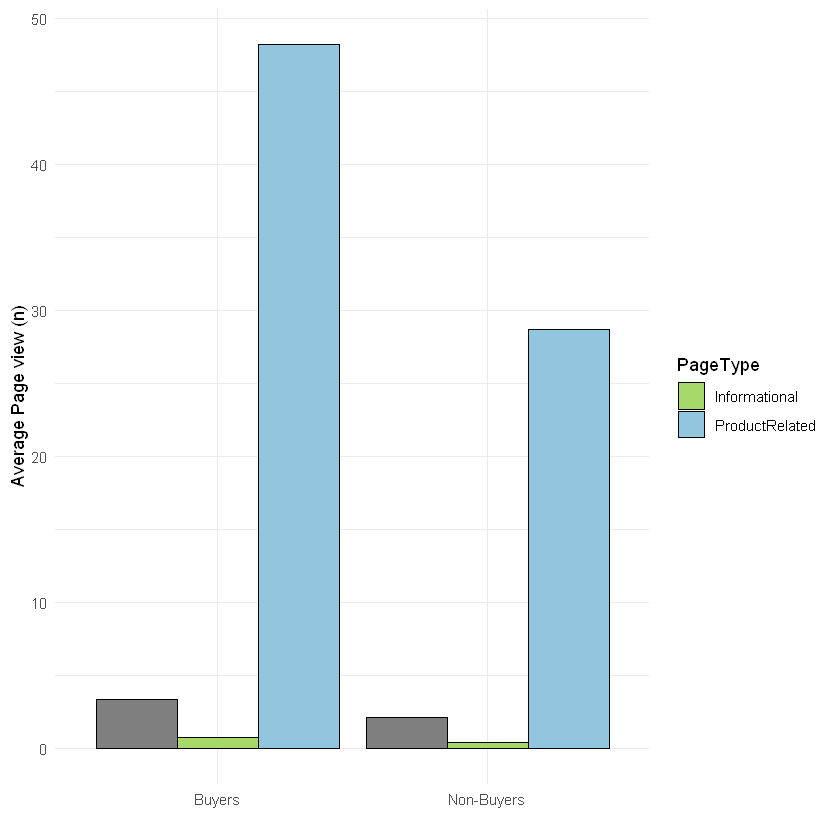

In [97]:
melted_df <- melt(page_cnt_df, id.vars = 'Revenue', measure.vars = c('Administrative', 'Informational', 'ProductRelated'),
                  variable.name = 'PageType', value.name = 'Value')
page_colors <- c('ProductRelated' = '#92c5de', 'Administrativen' = '#fdbf6f', 'Informational' = '#a6d96a')
# Plotting
ggplot(melted_df, aes(x = Revenue, y = Value, fill = PageType)) +
  geom_bar(stat = 'identity', position = 'dodge', color = 'black') +
  labs(x = '', y = 'Average Page view (n)') +
  scale_fill_manual(values = page_colors) +
  theme_minimal()

### 8) Visitor Type and Revenue Analysis

In [98]:
visitor_df <- myData %>%
    group_by(VisitorType, Revenue) %>%
    summarise(
        cnt = n()
        )
options(dplyr.summarise.inform = FALSE)

In [99]:
visitor_df <- visitor_df %>%
  mutate(Revenue = ifelse(Revenue == TRUE, 'Buyers', 'Non-Buyers'))

In [100]:
visitor_df

VisitorType,Revenue,cnt
<chr>,<chr>,<int>
New_Visitor,Non-Buyers,1272
New_Visitor,Buyers,422
Other,Non-Buyers,69
Other,Buyers,16
Returning_Visitor,Non-Buyers,9081
Returning_Visitor,Buyers,1470


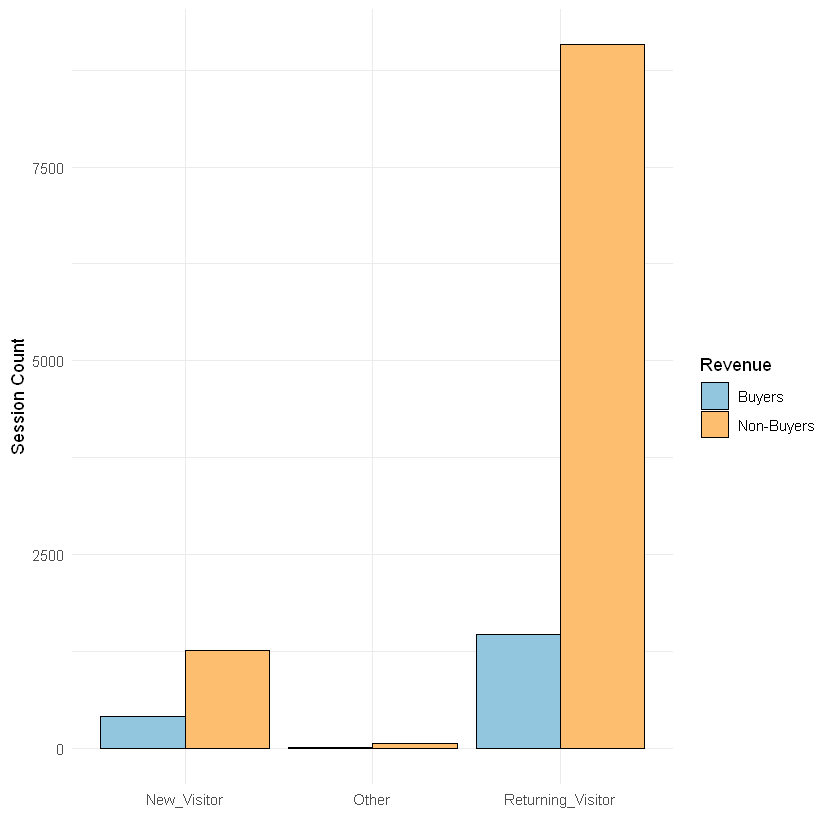

In [101]:
page_colors <- c('Buyers' = '#92c5de', 'Non-Buyers' = '#fdbf6f')

# Plotting
ggplot(visitor_df, aes(x = VisitorType, y = cnt, fill = Revenue)) +
  geom_bar(stat = 'identity', position = 'dodge', color = 'black') +
  labs(x = '', y = 'Session Count') +
  scale_fill_manual(values = page_colors) +
  theme_minimal()

### 9) Engagement Metrics and Revenue Analysis

`geom_smooth()` using formula = 'y ~ x'


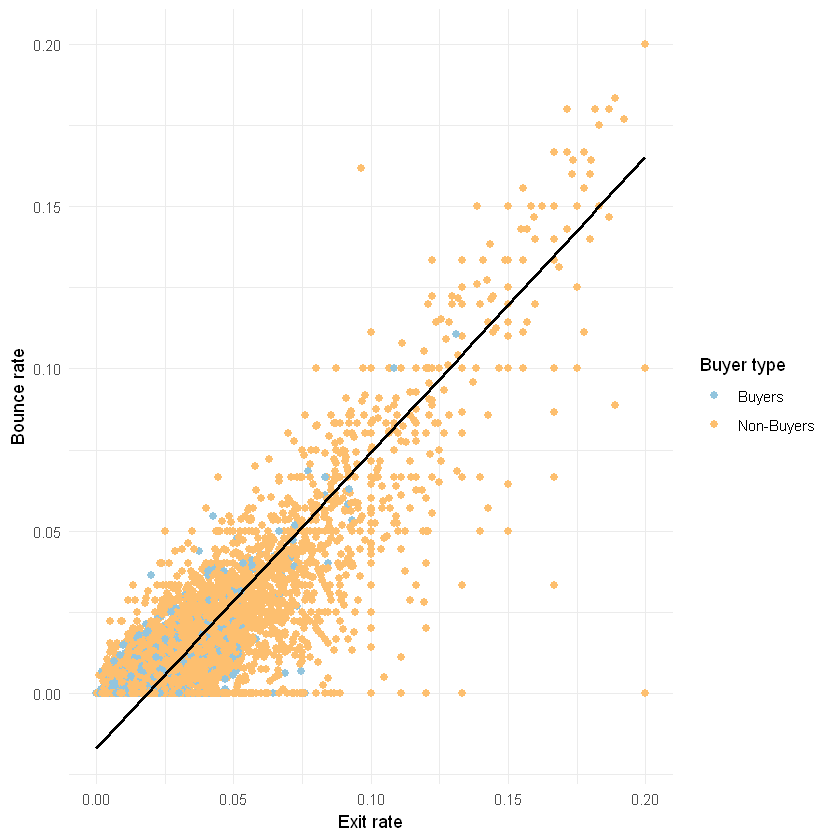

In [102]:
# Create a copy of the dataframe
df_bounce_exit <- myData

# Map True to 'Buyers' and False to 'Non-Buyers' in the 'Revenue' column
df_bounce_exit$Revenue <- ifelse(df_bounce_exit$Revenue, 'Buyers', 'Non-Buyers')

# Define custom colors
custom_colors <- c('Buyers' = '#92c5de', 'Non-Buyers' = '#fdbf6f')

# Scatterplot with custom colors
ggplot(df_bounce_exit, aes(x = ExitRates, y = BounceRates, color = Revenue)) +
  geom_point(size = 2) +
  scale_color_manual(values = custom_colors) +
  
  # Add regression line
  geom_smooth(method = 'lm', se = FALSE, color = 'black') +
  
  labs(x = 'Exit rate', y = 'Bounce rate', color = 'Buyer type') +
  theme_minimal()

### 10) Month and Revenue Analysis

In [103]:
# Filter data for buyers
buyers <- myData[myData$Revenue == TRUE, ]
# Group by Month and count buyers
buyers_count <- buyers %>%
  group_by(Month) %>%
  summarise(Buyers = n())

In [104]:
buyers_count

Month,Buyers
<fct>,<int>
Aug,76
Dec,216
Feb,3
Jul,66
Jun,29
Mar,192
May,365
Nov,760
Oct,115


In [105]:
# Define the correct order of month names
month_order <- c("Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec")
buyers_count$Month <- factor(buyers_count$Month, levels = month_order)
buyers_count <- buyers_count[order(buyers_count$Month), , drop = FALSE]

In [106]:
buyers_count

Month,Buyers
<fct>,<int>
Feb,3
Mar,192
May,365
Jun,29
Jul,66
Aug,76
Sep,86
Oct,115
Nov,760


In [107]:
# Filter data for non-buyers
non_buyers <- myData[myData$Revenue == FALSE, ]
# Group by Month and count non-buyers
non_buyers_count <- non_buyers %>%
  group_by(Month) %>%
  summarise(Non_Buyers = n())

non_buyers_count$Month <- factor(buyers_count$Month, levels = month_order)
non_buyers_count <- non_buyers_count[order(buyers_count$Month), , drop = FALSE]

In [108]:
non_buyers_count

Month,Non_Buyers
<fct>,<int>
Feb,357
Mar,1511
May,181
Jun,366
Jul,259
Aug,1715
Sep,2999
Oct,2238
Nov,434


In [109]:
# Merge the counts of buyers and non-buyers by month
month_customer <- merge(buyers_count, non_buyers_count, by = "Month", all = TRUE)

# Reshape data to long format
month_customer_long <- melt(month_customer, id.vars = "Month", variable.name = "Type", value.name = "SessionCount")

month_customer_long$Month <- factor(month_customer_long$Month, levels = month_order)
month_customer_long <- month_customer_long[order(month_customer_long$Month), , drop = FALSE]
rownames(month_customer_long) <- NULL

In [110]:
month_customer_long

Month,Type,SessionCount
<fct>,<fct>,<int>
Feb,Buyers,3
Feb,Non_Buyers,357
Mar,Buyers,192
Mar,Non_Buyers,1511
May,Buyers,365
May,Non_Buyers,181
Jun,Buyers,29
Jun,Non_Buyers,366
Jul,Buyers,66


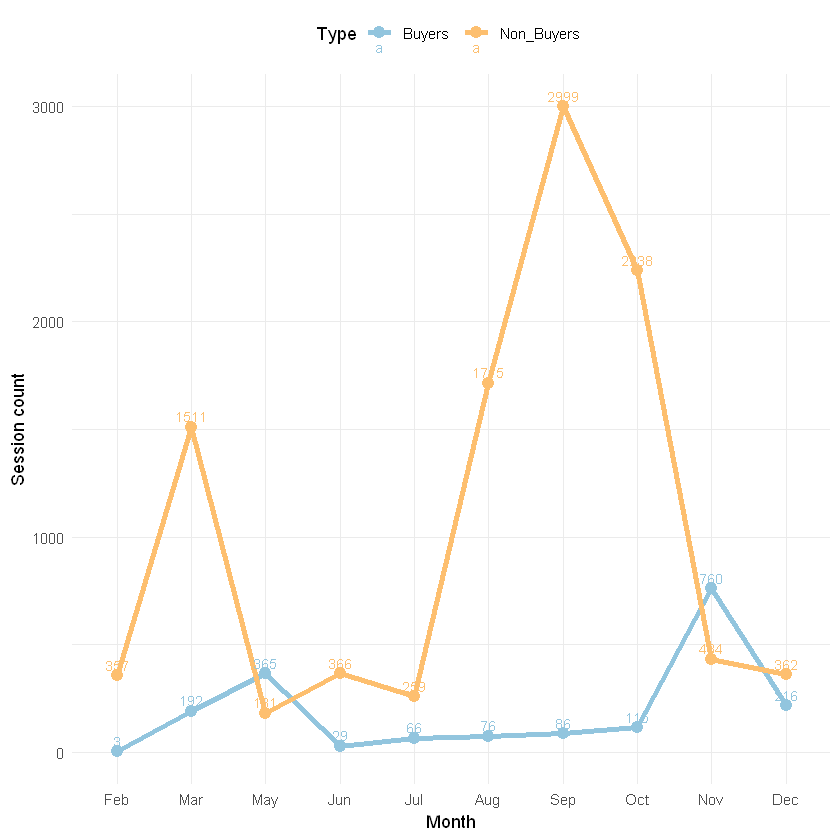

In [111]:
# Plotting
ggplot(month_customer_long, aes(x = Month, y = SessionCount, color = Type, group = Type)) +
  geom_line(size = 1.5, linetype = "solid") +
  geom_point(size = 3) +  # Removed shape aesthetic
  geom_text(aes(label = SessionCount), vjust = -0.5, hjust = 0.5, size = 3) +
  scale_color_manual(values = c("Buyers" = "#92c5de", "Non_Buyers" = "#fdbf6f"), name = "Type") +
  labs(x = "Month", y = "Session count") +
  theme_minimal() +
  theme(legend.position = "top")

## 2. Predicting Modeling

### 1) BART

In [186]:
# 1. Data Preprocessing
myData$Revenue <- ifelse(myData$Revenue, 1, 0)

In [187]:
dmy <- dummyVars(~., data = myData)
myData_withDummy <- data.frame(predict(dmy, newdata = myData))

In [188]:
# 2. selecting test dataset (30%)
testsize = as.integer(nrow(myData_withDummy)*0.3)
test_index = sort(sample(1:nrow(myData_withDummy),testsize,replace=F)) #random sampling for test data set
myData_test = myData_withDummy[test_index, ]
myData_train = myData_withDummy[-test_index, ]

In [189]:
# 3. Modeling with BART
# Convert the last column to double and format
myData_train[, length(myData_train)] <- as.double(myData_train[, length(myData_train)])
myData_test[, length(myData_test)] <- as.double(myData_test[, length(myData_train)])

myData_x.train = myData_train[, -length(myData_train)]
myData_y.train = myData_train[, length(myData_train)]
myData_x.test = myData_test[, -length(myData_test)]

# Use the bart function
bartmod1 <- bart(x.train = myData_x.train,
                 y.train = myData_y.train,
                 x.test = myData_x.test,
                 ntree = 75,
                 verbose = FALSE)

NOTE: assumming numeric response is binary


In [190]:
bart.y1 = t(bartmod1$yhat.test)
points.y1.est = rep(NA,testsize)

In [191]:
l <- list()  # Create an empty list
for (i in 1:testsize) {
  l[[i]] <- mean(bart.y1[i, ])
}
df <- data.frame(y_hat = unlist(l))

In [192]:
summary_stats <- summary(df$y_hat)

# Print summary statistics
print(summary_stats)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -3.440  -2.145  -1.716  -1.484  -1.060   1.652 


In [193]:
for(i in 1:testsize){
	points.y1.est[i] <-  ifelse(mean(bart.y1[i,]) >= threshold, 1, 0)
}

In [194]:
# 4. Confusion Matrix
cm_bart<-confusionMatrix(as.factor(points.y1.est), as.factor(myData_test[, length(myData_test)]))
cm_bart

Confusion Matrix and Statistics

          Reference
Prediction    0    1
         0 3025  288
         1  103  283
                                         
               Accuracy : 0.8943         
                 95% CI : (0.8839, 0.904)
    No Information Rate : 0.8456         
    P-Value [Acc > NIR] : < 2.2e-16      
                                         
                  Kappa : 0.5333         
                                         
 Mcnemar's Test P-Value : < 2.2e-16      
                                         
            Sensitivity : 0.9671         
            Specificity : 0.4956         
         Pos Pred Value : 0.9131         
         Neg Pred Value : 0.7332         
             Prevalence : 0.8456         
         Detection Rate : 0.8178         
   Detection Prevalence : 0.8956         
      Balanced Accuracy : 0.7313         
                                         
       'Positive' Class : 0              
                                         

In [195]:
# 5. accuracy, precision, recall, f1_score
accuracy <- cm_bart$overall['Accuracy']
precision <- cm_bart$byClass['Pos Pred Value']  # 또는 'Precision'
recall <- cm_bart$byClass['Sensitivity']
f1_score <- 2 * (precision * recall) / (precision + recall)

In [196]:
# print
print(paste("Accuracy:", round(accuracy, 4)))
print(paste("Precision:", round(precision, 4)))
print(paste("Recall:", round(recall, 4)))
print(paste("F1 Score:", round(f1_score, 4)))

[1] "Accuracy: 0.8943"
[1] "Precision: 0.9131"
[1] "Recall: 0.9671"
[1] "F1 Score: 0.9393"


### 2) Logistic Regression

In [197]:
# 1. Data Preprocessing
myData <- read.csv("online_shoppers_intention.csv")

In [198]:
myData$Month <- as.factor(myData$Month)
myData$OperatingSystems <- as.factor(myData$OperatingSystems)
myData$Browser <- as.factor(myData$Browser)
myData$Region <- as.factor(myData$Region)
myData$TrafficType <- as.factor(myData$TrafficType)

In [199]:
levels(myData$Month)[levels(myData$Month)=="June"] <- "Jun"

In [200]:
myData$Revenue <- ifelse(myData$Revenue, 1, 0)

In [201]:
numeric_list = c('Administrative', 'Administrative_Duration','Informational','Informational_Duration','ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Revenue')

In [202]:
dmy <- dummyVars(~ ., data = myData, fullRank = TRUE)
myData_withDummy <- data.frame(predict(dmy, newdata = myData))

In [203]:
# 2. selecting test dataset (30%)
#same data as BART
testsize <- as.integer(nrow(myData_withDummy) * 0.3)
test_index <- sort(sample(1:nrow(myData_withDummy), testsize, replace = FALSE))
myData_test <- myData_withDummy[test_index, ]
myData_train <- myData_withDummy[-test_index, ]

In [204]:
# 3. Modeling with logistic regression
logistic <- glm(Revenue ~ .,
		data = myData_train,
		family = binomial())

In [205]:
predictions <- predict(logistic, newdata = myData_test, type = "response")

In [206]:
# Convert predictions to factor with levels 0 and 1
binary_predictions <- factor(ifelse(predictions > threshold, 1, 0), levels = c(0, 1))
table(binary_predictions)

binary_predictions
   0    1 
2861  838 

In [208]:
# 4. Confusion Matrix
cm_lr <- confusionMatrix(binary_predictions, factor(myData_test[, length(myData_test)]))
print(cm_lr)

Confusion Matrix and Statistics

          Reference
Prediction    0    1
         0 2714  147
         1  432  406
                                         
               Accuracy : 0.8435         
                 95% CI : (0.8314, 0.855)
    No Information Rate : 0.8505         
    P-Value [Acc > NIR] : 0.8887         
                                         
                  Kappa : 0.4923         
                                         
 Mcnemar's Test P-Value : <2e-16         
                                         
            Sensitivity : 0.8627         
            Specificity : 0.7342         
         Pos Pred Value : 0.9486         
         Neg Pred Value : 0.4845         
             Prevalence : 0.8505         
         Detection Rate : 0.7337         
   Detection Prevalence : 0.7735         
      Balanced Accuracy : 0.7984         
                                         
       'Positive' Class : 0              
                                         


In [209]:
# 5. accuracy, precision, recall, f1_score
accuracy <- cm_lr$overall['Accuracy']
precision <- cm_lr$byClass['Pos Pred Value']  # 또는 'Precision'
recall <- cm_lr$byClass['Sensitivity']
f1_score <- 2 * (precision * recall) / (precision + recall)

In [210]:
# print
print(paste("Accuracy:", round(accuracy, 4)))
print(paste("Precision:", round(precision, 4)))
print(paste("Recall:", round(recall, 4)))
print(paste("F1 Score:", round(f1_score, 4)))

[1] "Accuracy: 0.8435"
[1] "Precision: 0.9486"
[1] "Recall: 0.8627"
[1] "F1 Score: 0.9036"
